# This notebook writes up the equations for an insurance market where insurers price their urplus captial costs


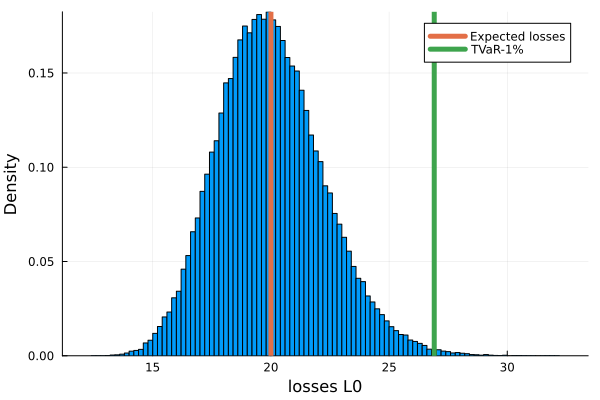

In [92]:
using Distributions, Random, Statistics, Plots

"""
    lognormal_mean_cv(m, cv)

Return a LogNormal distribution with mean `m` and coefficient of variation `cv`.
"""
function lognormal_mean_cv(m, cv)
    σ² = log1p(cv^2)          # log(1 + cv²), accurate for small cv
    μ  = log(m) - σ² / 2
    return LogNormal(μ, sqrt(σ²))
end


"""
    sample_L0([rng,] n_samples, n, Q, CV) -> Vector{Float64}

Monte Carlo samples of the total loss `L0` on the base portfolio
(all lines of business *excluding* the fisheries insurance line).

# Model
The portfolio has `n` independent, identically distributed lines of business.
The loss on line `i` is

    L_i = Q * X_i,    X_i ~ LogNormal with mean 1 and coefficient of variation CV

so each line has expected loss `Q` and standard deviation `Q * CV`.
The portfolio loss is `L0 = L_1 + ... + L_n`, with

    E[L0]  = n * Q
    SD[L0] = sqrt(n) * Q * CV

# Arguments
- `rng`       : (optional) random number generator, for reproducibility.
- `n_samples` : number of Monte Carlo draws of `L0`.
- `n`         : number of lines of business.
- `Q`         : exposure (expected loss) of each line.
- `CV`        : coefficient of variation of each line's loss.

# Returns
A vector of length `n_samples`, where each entry is one draw of `L0`.

# Example
```julia
samples = sample_L0(MersenneTwister(1), 100_000, 20, 1.0, 0.5)
```
"""
function sample_L0(rng::AbstractRNG, n_samples::Integer, n::Integer, Q::Real, CV::Real)
    d   = lognormal_mean_cv(1.0, CV)   # built once, not per draw
    out = Vector{Float64}(undef, n_samples)
    @inbounds for s in 1:n_samples
        total = 0.0
        for _ in 1:n
            total += rand(rng, d)      # no temporary arrays
        end
        out[s] = Q * total             # multiply once, not per line
    end
    return out
end

sample_L0(n_samples::Integer, n::Integer, Q::Real, CV::Real) =
    sample_L0(Random.default_rng(), n_samples, n, Q, CV)

"""
    tvar(samples, α) -> Float64

Empirical Tail Value-at-Risk (also called CTE or Expected Shortfall) at
confidence level `α`. It is the average of the worst `(1 - α)` share of losses.
For example, `α = 0.99` averages the worst 1% of samples.

It is computed as

    TVaR_α = VaR_α + E[(L - VaR_α)⁺] / (1 - α)

where `VaR_α` is the empirical `α`-quantile of the samples. This form handles
a fractional tail correctly when `(1 - α) * n` is not a whole number, by
giving the boundary sample only its fractional share of the weight.

# Arguments
- `samples` : vector of simulated losses (larger = worse).
- `α`       : confidence level, strictly between 0 and 1.
"""
function tvar(samples::AbstractVector{<:Real}, α::Real)
    0 < α < 1    || throw(ArgumentError("α must be in (0, 1), got $α"))
    n = length(samples)
    n > 0        || throw(ArgumentError("samples is empty"))

    k   = ceil(Int, α * n)             # position of the empirical α-quantile
    var = partialsort(samples, k)      # O(n), no full sort; doesn't modify samples
    excess = sum(x -> max(x - var, 0.0), samples) / n
    return var + excess / (1 - α)
end

# Usage
using Plots
n = 20
Q_base = 1.0
CV = 0.5
α = 0.99
samples = sample_L0(100_000, n, Q_base, CV)
TVaR = tvar(samples, α)
histogram(samples; normalize = :pdf, xlabel = "losses L0", ylabel = "Density", label = "")
vline!([n*Q_base],label = "Expected losses", width = 5)
vline!([TVaR],label = "TVaR-1%", width = 5)

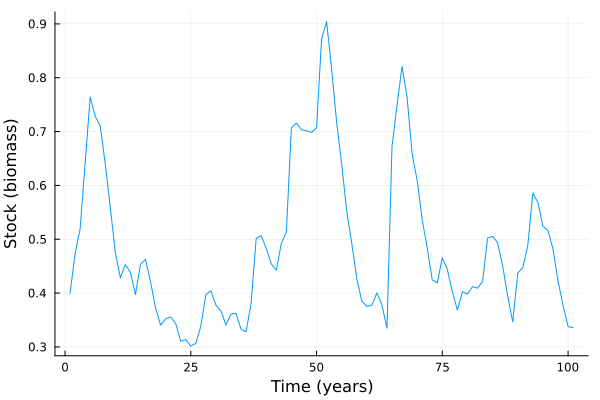

In [113]:
include("../src/population_model.jl")
include("../src/model.jl")
include("../parameters/RA_intermidiate.jl")
#include("../parameters/RA_short.jl")
pars = p                      # intermediate parameter set

"""
    build_sampler(p) -> Function

Return a zero-argument closure that draws the stochastic drivers of the stock
for one year, as a length-4 vector

    [μZ, μ_P, μ_Ce, ε_R],    ε_R ~ Normal(0, σ_R)

The first three entries are the fixed means from the parameter set `p`; the last is
a fresh recruitment shock on each call. The result is used as the sampler of an
`MCRandomVariable`.

# Arguments
- `p` : parameter set with fields `μZ`, `μ_P`, `μ_Ce` and `σ_R`.
"""
function build_sampler(p)
    function sampler()
        return [p.μZ, p.μ_P, p.μ_Ce, rand(Distributions.Normal(0, p.σ_R))]
    end
    return sampler
end

T_   = 100                     # years to simulate

X2   = MarkovChain(pars.T)    # Markov chain on the mortality transition, from the transition matrix
Xmc  = MCRandomVariable(build_sampler(pars), X2, 1)
states, m, f, h, y = simulate_trajectory(pars, Xmc, T_)

plot(exp.(states[1,:]), xlab = "Time (years)", ylab = "Stock (biomass)", label = "")

In [ ]:
using StatsBase   # sample, Weights

"""
    sample_stock(s0, p, z, u) -> Float64 or Vector{Float64}

Draw the stock biomass one year ahead of `s0`, driven by explicit random numbers
so that the same draws can be reused across initial states, parameter sets or
strikes (common random numbers).

`z` is a standard normal draw, scaled by `p.σ_R` to give the recruitment shock.
`u` is a uniform(0, 1) draw used to sample the next mortality state from the
Markov chain. With vectors `z` and `u` (same length) the method returns one
biomass per pair.

# Arguments
- `s0` : current state `(log stock, change in log stock, mortality state)`, e.g. a
         column of `states` from `simulate_trajectory`.
- `p`  : population-model parameter set (e.g. `pars`).
- `z`  : standard normal draw(s) for the recruitment shock.
- `u`  : uniform(0, 1) draw(s) for the Markov-chain transition.

# Returns
Next-year biomass `exp(s1[1])`: a number for scalar `z, u`, or a vector for vector inputs.

# Example
```julia
z = randn(1000);  u = rand(1000)
B1 = sample_stock(states[:, 25], pars, z, u)
```
"""
function sample_stock(s0, p, z::Real, u::Real)
    s1, h, f = update_stock(s0, [p.σ_R * z, u], p)
    return exp(s1[1])
end

function sample_stock(s0, p, z::Vector{}, u::Vector{})
    s1 = broadcast(i -> update_stock(s0, [p.σ_R * z[i], u[i]], p)[1][1], 1:length(u))
    return exp.(s1)
end


function parametric_payout(s,strike)
    return  max(strike.-s,0)
end


s0 = states[:,17] #states[:, 40]
strike_ = 0.4
Nmc = 100_000
z = rand(Normal(0,1),Nmc)
u = rand(Nmc)
s1_samples = sample_stock(s0, pars, z, u)
histogram(parametric_payout.(s1_samples,strike_),
             xlabel = "Parametric payout", ylabel = "Count", label = "",
             bins = 100)

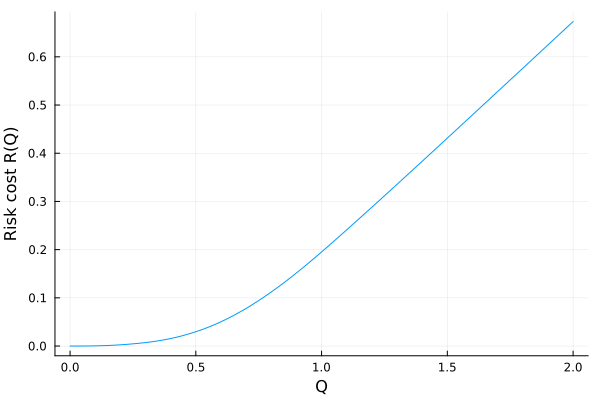

In [222]:
using Statistics

"""
    S(Q, L0, x, α) -> Float64

Swiss Solvency Test (SST) capital requirement for the portfolio
`L = L0 + Q * x`.

The SST measures risk as the Expected Shortfall (TVaR) of the one-year loss at
confidence level `α` (`α = 0.99` in the SST), counted in excess of the expected
loss:

    S(Q) = TVaR_α(L) - E[L],    L = L0 + Q x

The expected loss is assumed to be covered by premiums. `S(Q)` is the
additional capital the insurer must hold to absorb losses in the worst
`(1 - α)` share of outcomes.

# Arguments
- `Q`  : exposure to the added (fisheries) line. `Q = 0` gives the base
         portfolio alone.
- `L0` : Monte Carlo samples of the base-portfolio loss (e.g. from `sample_L0`).
- `x`  : Monte Carlo samples of the per-unit payout of the added line, paired
         element by element with `L0`. Each pair `L0[i] + Q * x[i]` is one
         scenario.
- `α`  : Expected Shortfall confidence level, strictly between 0 and 1
         (`0.99` for the SST).

# Returns
The SST capital requirement, in the same units as the losses.
"""
function S(Q::Real, L0::AbstractVector{<:Real},
           x::AbstractVector{<:Real}, α::Real)
    length(L0) == length(x) ||
        throw(DimensionMismatch("L0 has $(length(L0)) samples but x has $(length(x))"))
    L = L0 .+ Q .* x
    return tvar(L, α) - mean(L)
end

"""
    R(Q, L0, x, α, τ) -> Float64

Risk cost of taking on exposure `Q` to the added line: the yearly cost of
holding the extra SST capital that this line requires,

    R(Q) = τ * (S(Q) - S(0))

where `S` is the SST capital requirement (see [`S`](@ref)) and `τ` is the cost
of holding surplus capital: the return shareholders require on capital beyond
the risk-free rate. The SST market value margin uses `τ = 0.06`.

`S(Q) - S(0)` is the *marginal* capital, the extra capital needed because the
new line is added to the existing portfolio. Diversification against `L0` means
it is usually less than the capital the line would need on its own.

# Arguments
- `Q`, `L0`, `x`, `α` : as in [`S`](@ref).
- `τ` : cost-of-capital rate (e.g. `0.06`).

# Returns
The risk cost, in the same units as the losses (per year).
"""
function R(Q::Real, L0::AbstractVector{<:Real},
           x::AbstractVector{<:Real}, α::Real, τ::Real)
    return τ * (S(Q, L0, x, α) - S(0, L0, x, α))
end

# Usage
α = 0.99      # SST Expected Shortfall level
τ = 0.06      # cost of capital

L0        = sample_L0(100_000, n, Q_base, CV)
z         = randn(100_000);  u = rand(100_000)
s_samples = sample_stock(s0, pars, z, u)
x_raw     = parametric_payout.(s_samples, strike_)
x         = x_raw ./ mean(x_raw)      # normalise so E[x] = 1, i.e. E[Q x] = Q

Q_range = 0:0.025:2
R_range = [R(q, L0, x, α, τ) for q in Q_range]
plot(Q_range, R_range; xlabel = "Q", ylabel = "Risk cost R(Q)", label = "")

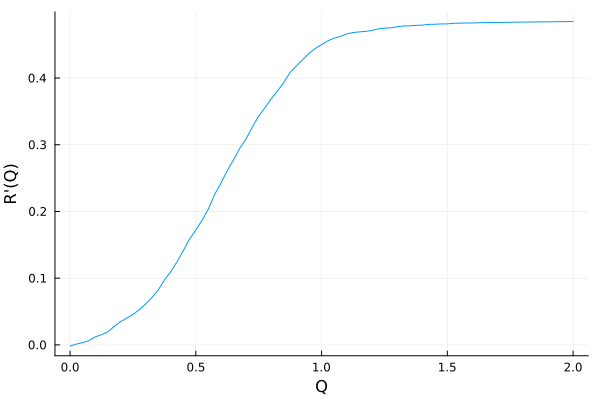

In [223]:
"""
    dS(Q, L0, x, α) -> Float64

Derivative of the SST capital requirement with respect to exposure:
`S'(Q) = d/dQ [TVaR_α(L0 + Q x) - E[L0 + Q x]]`.

Computed in closed form as

    S'(Q) = E[x | L ≥ VaR_α(L)] - E[x],    L = L0 + Q x

which is the exact derivative of the empirical `tvar` estimator (the boundary
scenario gets its fractional tail weight). The result is the line's
contribution to tail risk per unit of exposure.

# Arguments
As in [`S`](@ref).
"""
function dS(Q::Real, L0::AbstractVector{<:Real},
            x::AbstractVector{<:Real}, α::Real)
    length(L0) == length(x) ||
        throw(DimensionMismatch("L0 has $(length(L0)) samples but x has $(length(x))"))
    n = length(L0)
    L = L0 .+ Q .* x

    k   = ceil(Int, α * n)
    j   = partialsortperm(L, k)      # scenario sitting at VaR_α
    var = L[j]
    w   = 1 / (n * (1 - α))          # tail weight per scenario

    tail_sum = 0.0
    m = 0                            # scenarios strictly beyond VaR
    @inbounds for i in eachindex(L)
        if L[i] > var
            tail_sum += x[i]
            m += 1
        end
    end
    dtvar = w * tail_sum + (1 - m * w) * x[j]   # boundary scenario gets the leftover weight
    return dtvar - mean(x)
end

"""
    dR(Q, L0, x, α, τ) -> Float64

Marginal risk cost `R'(Q) = τ * S'(Q)`: the extra yearly cost of capital from
one more unit of exposure to the added line. See [`dS`](@ref) and [`R`](@ref).
"""
dR(Q::Real, L0::AbstractVector{<:Real}, x::AbstractVector{<:Real},
   α::Real, τ::Real) = τ * dS(Q, L0, x, α)

# Usage
dR_range = [dR(q, L0, x, α, τ) for q in Q_range]
plot(Q_range, dR_range; xlabel = "Q", ylabel = "R'(Q)", label = "")

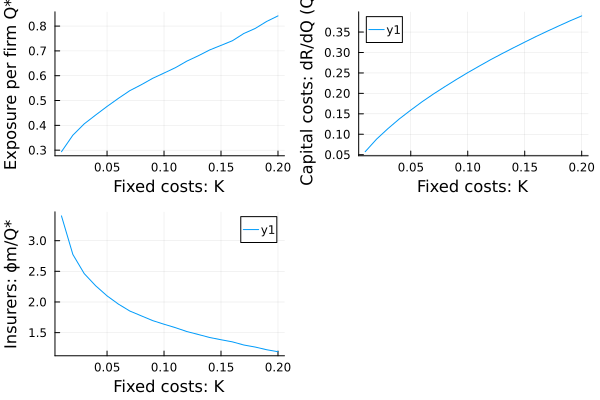

In [224]:
using Roots

"""
    equilibrium_residual(Q, K, R, dR) -> Float64

Competitive equilibrium condition: inframarginal rents minus participation
cost,

    f(Q) = Q R'(Q) - [R(Q) - R(0)] - K

Insurers price at the marginal risk cost `R'(Q)`, so the rent they earn above
their actual risk cost on exposure `Q` is `Q R'(Q) - [R(Q) - R(0)]`. In
equilibrium this rent just covers the fixed participation cost `K`, so
`f(Q) = 0`.
"""
equilibrium_residual(Q, K, R, dR) = Q * dR(Q) - (R(Q) - R(0.0)) - K

"""
    equilibrium_Q(K, R, dR; Q_hi = 1.0, Q_max = 1e6) -> Float64

Solve the competitive equilibrium condition `f(Q) = 0` for the equilibrium
exposure `Q*` (see [`equilibrium_residual`](@ref)).

# Arguments
- `K`  : participation cost (> 0), in the same per-year units as `R`.
- `R`  : function `Q -> R(Q)`, the risk cost.
- `dR` : function `Q -> R'(Q)`, the marginal risk cost.

# Keywords
- `Q_hi`  : initial guess for the upper end of the search range. It is doubled
            until `f(Q_hi) > 0`.
- `Q_max` : give up if no root is found below this value. This happens when
            rents never grow large enough to cover `K`, e.g. when `R` is not
            convex enough.

# Method
`f(0) = -K < 0`, and `f` increases in `Q` when `R` is convex. The function
brackets the root and then bisects, which stays reliable even though the
Monte Carlo `R'` is noisy.
"""
function equilibrium_Q(K::Real, R, dR; Q_hi::Real = 1.0, Q_max::Real = 1e6)
    K > 0 || throw(ArgumentError("K must be positive, got $K"))
    f(Q) = equilibrium_residual(Q, K, R, dR)

    while f(Q_hi) < 0
        Q_hi *= 2
        Q_hi <= Q_max || error("no equilibrium found for Q ≤ $Q_max: " *
                               "rents Q R'(Q) - [R(Q) - R(0)] never reach K = $K")
    end
    return find_zero(f, (0.0, Q_hi), Bisection())
end

# Usage: fix the samples and parameters in closures
Rq  = q -> R(q, L0, x, α, τ)
dRq = q -> dR(q, L0, x, α, τ)

K = 0.05
Q_star = equilibrium_Q(K, Rq, dRq)

# Equilibrium Q across a range of participation costs
K_range = 0.01:0.01:0.2
Q_star_range = [equilibrium_Q(k, Rq, dRq) for k in K_range]
p1 = plot(K_range, Q_star_range; xlabel = "Fixed costs: K", 
        ylabel = "Exposure per firm Q*", label = "")
p2 = plot(K_range, dRq.(Q_star_range); xlabel = "Fixed costs: K",
         ylabel = "Capital costs: dR/dQ (Q*)")
p3 = plot(K_range, 1 ./Q_star_range; xlabel = "Fixed costs: K",
         ylabel = "Insurers: ϕm/Q*")

plot(p1,p2,p3)

In [235]:
"""
    capital_costs(s0, strike_, pars, K, n, Q_base, CV, α, τ; Nmc = 20_000, seed = 1) -> Float64

Marginal capital cost `R'(Q*)` at the competitive equilibrium exposure `Q*`, for
a fisheries index line written from initial stock state `s0`. Returns `0` if no
equilibrium is found.

The same random numbers (seeded by `seed`) drive the base portfolio `L0` and the
stock draws `(z, u)` on every call, so results for different `s0` are comparable
without Monte Carlo noise between them. Note that `α` and `τ` are currently reset
to 0.99 and 0.06 inside the function.
"""
function capital_costs(s0, strike_, pars, K, n, Q_base, CV, α, τ; Nmc = 20_000, seed = 1)

    α = 0.99      # SST Expected Shortfall level
    τ = 0.06      # cost of capital

    # common random numbers: identical for every s0
    rng = Random.Xoshiro(seed)
    L0  = sample_L0(rng, Nmc, n, Q_base, CV)
    z   = randn(rng, Nmc)
    u   = rand(rng, Nmc)

    s_samples = sample_stock(s0, pars, z, u)
    x_raw     = parametric_payout.(s_samples, strike_)
    x         = x_raw ./ mean(x_raw)      # normalise so E[x] = 1, i.e. E[Q x] = Q

    Rq = q -> R(q, L0, x, α, τ) 
    dRq = q -> dR(q, L0, x,α, τ) 
    try 
        Q_star = equilibrium_Q(K, Rq, dRq)
        return dRq(Q_star)
    catch 
        return 0
    end 
end 

include("../parameters/RA_intermidiate.jl")
pars = p    
strike_ = 0.3
K = 0.025
Q_base = 1.0
T_ = 250
burnin = 50
states, m, f, h, y = simulate_trajectory(pars, Xmc, T_)
costs = zeros(T_-burnin+1)
biomass = zeros(T_-burnin+1)
lag = zeros(T_-burnin+1)
for i in burnin:T_
    if mod(i,10) == 0 print(i-burnin+1, " ") end
    costs[i-burnin+1] = capital_costs(states[:,i], strike_, pars,  K, n, Q_base, CV, α, τ )
    biomass[i-burnin+1] = exp(states[1,i])
    lag[i-burnin+1] = states[2,i]
end

nothing

1 11 21 31 41 51 61 71 81 91 101 111 121 131 141 151 161 171 181 191 201 

In [236]:
include("../parameters/RA_short.jl")
pars = p    
 
K = 0.025
Q_base = 1.0
T_ = 250
burnin = 50
states, m, f, h, y = simulate_trajectory(pars, Xmc, T_)
costs_short = zeros(T_-burnin+1)
biomass_short = zeros(T_-burnin+1)
lag_short = zeros(T_-burnin+1)
for i in burnin:T_
    if mod(i,10) == 0 print(i-burnin+1, " ") end
    costs_short[i-burnin+1] = capital_costs(states[:,i], strike_, pars,  K, n, Q_base, CV, α, τ, Nmc=10_000)
    biomass_short[i-burnin+1] = exp(states[1,i])
    lag_short[i-burnin+1] = states[2,i]
end
nothing

1 11 21 31 41 51 61 71 81 91 101 111 121 131 141 151 161 171 181 191 201 

In [237]:
include("../parameters/RA_long.jl")
pars = p    
 
K = 0.025
Q_base = 1.0
T_ = 250
burnin = 50
states, m, f, h, y = simulate_trajectory(pars, Xmc, T_)
costs_long = zeros(T_-burnin+1)
biomass_long = zeros(T_-burnin+1)
lag_long = zeros(T_-burnin+1)
for i in burnin:T_
    if mod(i,10) == 0 print(i-burnin+1, " ") end
    costs_long[i-burnin+1] = capital_costs(states[:,i], strike_, pars,  K, n, Q_base, CV, α, τ, Nmc=1000)
    biomass_long[i-burnin+1] = exp(states[1,i])
    lag_long[i-burnin+1] = states[2,i]
end

nothing

1 11 21 31 41 51 61 71 81 91 101 111 121 131 141 151 161 171 181 191 201 

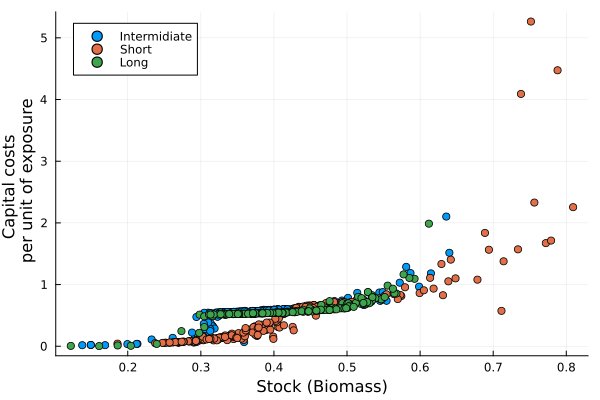

In [238]:
scatter(biomass[costs.!=0],costs[costs.!=0], label = "Intermidiate")
scatter!(biomass_short[costs_short.!=0],costs_short[costs_short.!=0], label = "Short")
scatter!(biomass_long[costs_long.!=0],costs_long[costs_long.!=0],label = "Long")
plot!(xlabel = "Stock (Biomass)", ylabel = "Capital costs \n per unit of exposure")